In [1]:
import pandas as pd

df = pd.read_csv("../Datasets/dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (614, 13)


In [2]:
df.head()


,loan_id,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,loan_status
0,lp001002,male,no,0,graduate,no,5849,0.0,NaN,360.0,1.0,urban,y
1,lp001003,male,yes,1,graduate,no,4583,1508.0,128.0,360.0,1.0,rural,n
2,lp001005,male,yes,0,graduate,yes,3000,0.0,66.0,360.0,1.0,urban,y
3,lp001006,male,yes,0,not graduate,no,2583,2358.0,120.0,360.0,1.0,urban,y
4,lp001008,male,no,0,graduate,no,6000,0.0,141.0,360.0,1.0,urban,y


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   loan_id            614 non-null    str    
 1   gender             601 non-null    str    
 2   married            611 non-null    str    
 3   dependents         599 non-null    str    
 4   education          614 non-null    str    
 5   self_employed      582 non-null    str    
 6   applicantincome    614 non-null    int64  
 7   coapplicantincome  614 non-null    float64
 8   loanamount         592 non-null    float64
 9   loan_amount_term   600 non-null    float64
 10  credit_history     564 non-null    float64
 11  property_area      614 non-null    str    
 12  loan_status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [4]:
df.isnull().sum()

loan_id               0
gender               13
married               3
dependents           15
education             0
self_employed        32
applicantincome       0
coapplicantincome     0
loanamount           22
loan_amount_term     14
credit_history       50
property_area         0
loan_status           0
dtype: int64

In [5]:
df["loan_status"].value_counts()

loan_status
y    422
n    192
Name: count, dtype: int64

In [6]:
df["loan_status"].value_counts(normalize=True) * 100

loan_status
y    68.729642
n    31.270358
Name: proportion, dtype: float64

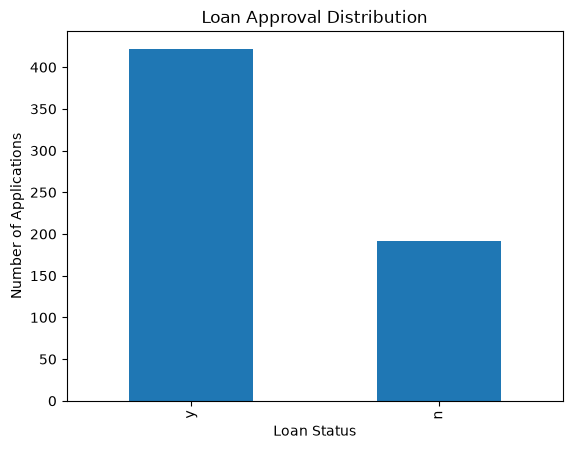

In [7]:
import matplotlib.pyplot as plt

df["loan_status"].value_counts().plot(kind="bar")

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()

In [8]:
categorical_columns = [
    "gender",
    "married",
    "dependents",
    "education",
    "self_employed",
    "property_area"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


gender:
gender
male      489
female    112
NaN        13
Name: count, dtype: int64

married:
married
yes    398
no     213
NaN      3
Name: count, dtype: int64

dependents:
dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64

education:
education
graduate        480
not graduate    134
Name: count, dtype: int64

self_employed:
self_employed
no     500
yes     82
NaN     32
Name: count, dtype: int64

property_area:
property_area
semiurban    233
urban        202
rural        179
Name: count, dtype: int64


In [9]:
df.describe()

,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


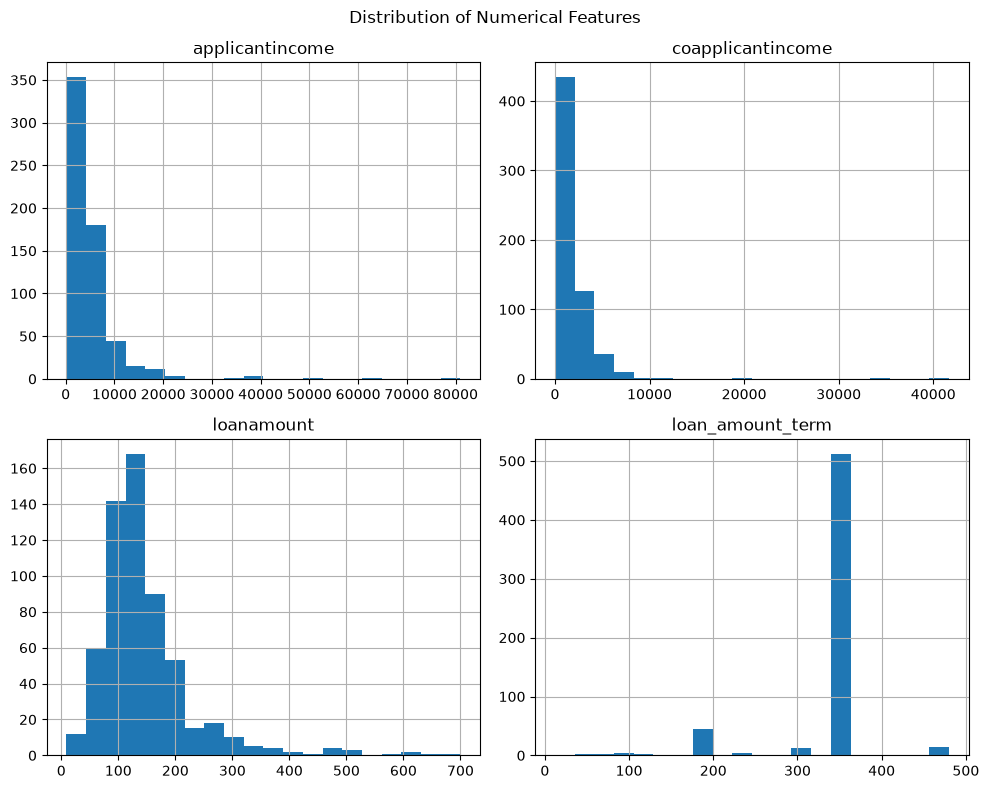

In [10]:
import matplotlib.pyplot as plt

numerical_columns = [
    "applicantincome",
    "coapplicantincome",
    "loanamount",
    "loan_amount_term"
]

df[numerical_columns].hist(figsize=(10, 8), bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd

pd.crosstab(df["credit_history"], df["loan_status"], normalize="index") * 100

loan_status,n,y
credit_history,,
0.0,92.134831,7.865169
1.0,20.421053,79.578947


In [12]:
pd.crosstab(df["property_area"], df["loan_status"], normalize="index") * 100

loan_status,n,y
property_area,,
rural,38.547486,61.452514
semiurban,23.175966,76.824034
urban,34.158416,65.841584


In [13]:
pd.crosstab(df["education"], df["loan_status"], normalize="index") * 100

loan_status,n,y
education,,
graduate,29.166667,70.833333
not graduate,38.805970,61.194030


In [14]:
pd.crosstab(df["married"], df["loan_status"], normalize="index") * 100

loan_status,n,y
married,,
no,37.089202,62.910798
yes,28.391960,71.608040


In [15]:
df.groupby("loan_status")["applicantincome"].agg(["mean", "median", "min", "max"])

,mean,median,min,max
loan_status,,,,
n,5446.078125,3833.5,150,81000
y,5384.068720,3812.5,210,63337


In [16]:
df.groupby("loan_status")["loanamount"].agg(["mean", "median", "min", "max"])

,mean,median,min,max
loan_status,,,,
n,151.220994,129.0,9.0,570.0
y,144.294404,126.0,17.0,700.0


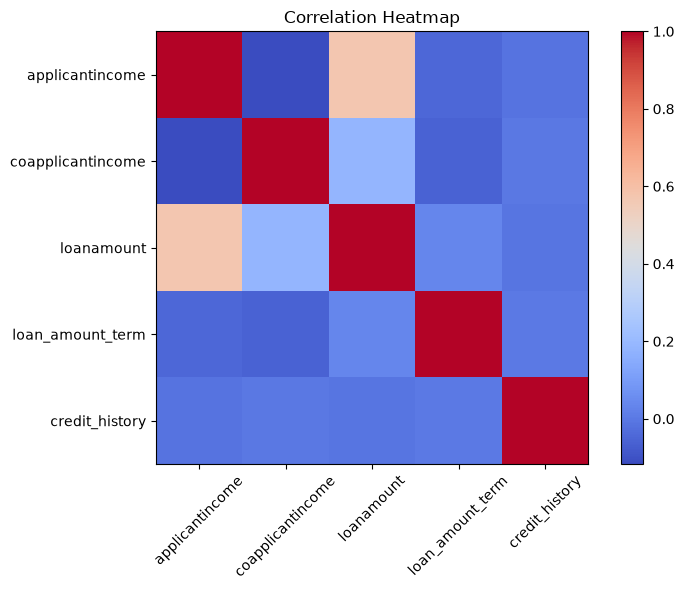

In [17]:
import matplotlib.pyplot as plt

correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 6))
plt.imshow(correlation, cmap="coolwarm", interpolation="none")
plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [18]:
df_processed = df.copy()

print("Copy created successfully!")
print(df_processed.shape)

Copy created successfully!
(614, 13)


In [19]:
print("Categorical modes:")
print(df_processed[["gender", "married", "dependents", "self_employed"]].mode().iloc[0])

print("\nNumerical medians:")
print(df_processed[["loanamount", "loan_amount_term"]].median())

print("\nCredit history mode:")
print(df_processed["credit_history"].mode().iloc[0])

Categorical modes:
gender           male
married           yes
dependents          0
self_employed      no
Name: 0, dtype: str

Numerical medians:
loanamount          128.0
loan_amount_term    360.0
dtype: float64

Credit history mode:
1.0


In [20]:
# Fill missing categorical values with the mode
categorical_columns = ["gender", "married", "dependents", "self_employed"]

for column in categorical_columns:
    df_processed[column] = df_processed[column].fillna(
        df_processed[column].mode()[0]
    )

# Fill missing numerical values with the median
numerical_columns = ["loanamount", "loan_amount_term"]

for column in numerical_columns:
    df_processed[column] = df_processed[column].fillna(
        df_processed[column].median()
    )

# Fill missing credit history with its mode
df_processed["credit_history"] = df_processed["credit_history"].fillna(
    df_processed["credit_history"].mode()[0]
)

print("Missing values handled successfully!")

Missing values handled successfully!


In [21]:
df_processed.isnull().sum()

loan_id              0
gender               0
married              0
dependents           0
education            0
self_employed        0
applicantincome      0
coapplicantincome    0
loanamount           0
loan_amount_term     0
credit_history       0
property_area        0
loan_status          0
dtype: int64

In [22]:
df_processed.select_dtypes(include="object").columns

C:\Users\polis\AppData\Local\Temp\ipykernel_1904\4027151476.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_processed.select_dtypes(include="object").columns


Index(['loan_id', 'gender', 'married', 'dependents', 'education',
       'self_employed', 'property_area', 'loan_status'],
      dtype='str')

In [23]:
# Remove the identifier column
df_processed = df_processed.drop(columns=["loan_id"])

# Convert the target variable to numbers
df_processed["loan_status"] = df_processed["loan_status"].map({
    "Y": 1,
    "N": 0
})

print(df_processed.head())
print("\nTarget values:")
print(df_processed["loan_status"].value_counts())

  gender married dependents     education self_employed  applicantincome  \
0   male      no          0      graduate            no             5849   
1   male     yes          1      graduate            no             4583   
2   male     yes          0      graduate           yes             3000   
3   male     yes          0  not graduate            no             2583   
4   male      no          0      graduate            no             6000   

   coapplicantincome  loanamount  loan_amount_term  credit_history  \
0                0.0       128.0             360.0             1.0   
1             1508.0       128.0             360.0             1.0   
2                0.0        66.0             360.0             1.0   
3             2358.0       120.0             360.0             1.0   
4                0.0       141.0             360.0             1.0   

  property_area  loan_status  
0         urban          NaN  
1         rural          NaN  
2         urban          NaN 

In [24]:
# Start again from the original raw dataset
df_processed = df.copy()

# Handle missing categorical values
categorical_columns = ["gender", "married", "dependents", "self_employed"]

for column in categorical_columns:
    df_processed[column] = df_processed[column].fillna(
        df_processed[column].mode()[0]
    )

# Handle missing numerical values
numerical_columns = ["loanamount", "loan_amount_term"]

for column in numerical_columns:
    df_processed[column] = df_processed[column].fillna(
        df_processed[column].median()
    )

# Handle missing credit history
df_processed["credit_history"] = df_processed["credit_history"].fillna(
    df_processed["credit_history"].mode()[0]
)

# Remove ID column
df_processed = df_processed.drop(columns=["loan_id"])

# Convert target: y = 1, n = 0
df_processed["loan_status"] = df_processed["loan_status"].map({
    "y": 1,
    "n": 0
})

print(df_processed.head())
print("\nLoan status values:")
print(df_processed["loan_status"].value_counts())


  gender married dependents     education self_employed  applicantincome  \
0   male      no          0      graduate            no             5849   
1   male     yes          1      graduate            no             4583   
2   male     yes          0      graduate           yes             3000   
3   male     yes          0  not graduate            no             2583   
4   male      no          0      graduate            no             6000   

   coapplicantincome  loanamount  loan_amount_term  credit_history  \
0                0.0       128.0             360.0             1.0   
1             1508.0       128.0             360.0             1.0   
2                0.0        66.0             360.0             1.0   
3             2358.0       120.0             360.0             1.0   
4                0.0       141.0             360.0             1.0   

  property_area  loan_status  
0         urban            1  
1         rural            0  
2         urban            1 

In [25]:
# One-hot encode categorical features
df_processed = pd.get_dummies(
    df_processed,
    columns=[
        "gender",
        "married",
        "dependents",
        "education",
        "self_employed",
        "property_area"
    ],
    drop_first=True
)

print("Categorical encoding completed!")
print("New shape:", df_processed.shape)
print(df_processed.head())

Categorical encoding completed!
New shape: (614, 15)
   applicantincome  coapplicantincome  loanamount  loan_amount_term  \
0             5849                0.0       128.0             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   credit_history  loan_status  gender_male  married_yes  dependents_1  \
0             1.0            1         True        False         False   
1             1.0            0         True         True          True   
2             1.0            1         True         True         False   
3             1.0            1         True         True         False   
4             1.0            1         True        False         False   

   dependents_2  dependents_3+  education_not graduate  self_employed_yes  

In [26]:
# Separate input features and target
X = df_processed.drop("loan_status", axis=1)
y = df_processed["loan_status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (614, 14)
Target shape: (614,)

Feature columns:
['applicantincome', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history', 'gender_male', 'married_yes', 'dependents_1', 'dependents_2', 'dependents_3+', 'education_not graduate', 'self_employed_yes', 'property_area_semiurban', 'property_area_urban']
